## Klasterisasi Puskesmas Berdasarkan Indikator Stunting Menggunakan K-Means sebagai Pendukung Penentuan Wilayah Prioritas Penanganan di Dinas Kesehatan Kota Padang

**Tugas Besar Machine Learning – Kelompok 8 | Pendukung penentuan wilayah prioritas, Dinas Kesehatan Kota Padang**


## 4 metrik yang dipakai
| # | Metrik | Pertanyaan yang dijawab | Cara membaca |
|---|---|---|---|
| 1 | **Silhouette** | Apakah tiap puskesmas lebih mirip kelompoknya sendiri daripada kelompok lain? | 0,5 atau lebih = kuat; 0,25–0,5 = lemah; di bawah 0,25 = tidak ada struktur |
| 2 | **Elbow (Inertia)** | Berapa jumlah kelompok (K) yang cukup? | Cari "siku": titik setelah itu penurunan melandai |
| 3 | **ARI antarperiode** | Apakah pola kelompok sama bila dihitung dari bulan yang berbeda? | 0 sampai 1. 0,7 atau lebih = baik; 0,5–0,7 = sedang; di bawah 0,5 = rendah |
| 4 | **Bootstrap keanggotaan** | Apakah sebuah puskesmas tetap di kelompoknya bila sampel anak diacak ulang 300 kali, dan apakah ia tidak berada di perbatasan kelompok? | Pasti = tetap sekelompok di 70% pengulangan atau lebih **dan** silhouette-nya tidak negatif |

Satu aturan tambahan (bukan metrik): setiap kelompok harus berisi **minimal 3 puskesmas**, karena kelompok berisi 1–2 puskesmas tidak berguna untuk kebijakan.

## 12 tahap
| # | Tahap | Isi singkat |
|---|---|---|
| 1 | Problem Definition | Masalah dan tujuan |
| 2 | Data Collection | Memuat 3 file BNBA |
| 3 | EDA | Memeriksa kualitas data |
| 4 | Data Preprocessing | Membersihkan data |
| 5 | Feature Engineering & Selection | Membuat 5 indikator per puskesmas |
| 6 | Data Splitting | Latih Maret–April, uji Mei (**Metrik 3**) |
| 7 | Model Selection | K-Means lawan Ward (**Metrik 1**) |
| 8 | Model Training | Melatih model, profil dan usulan per kelompok |
| 9 | Hyperparameter Tuning | Memilih K (**Metrik 1 dan 2**) |
| 10 | Model Evaluation | Silhouette akhir, bootstrap (**Metrik 4**), kartu skor, hasil akhir |
| 11 | Finalisasi Model | Menyimpan model |
| 12 | Deployment & Monitoring | Memakai model untuk bulan baru |

**Pembagian kerja:** Dhyva (Tahap 1–5), Aqila (Tahap 6–10), Madani (Tahap 11-12)

In [7]:
# ==== SEL 1: PERSIAPAN ====
import os, glob, json, datetime, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 40)

# ---- Pengaturan utama ----
SEED = 42                  # angka awal pengacak: seed sama = hasil sama
K = 3                      # jumlah kelompok = 3 tingkat prioritas Dinkes
N_INIT = 30                # berapa kali K-Means dicoba dari titik awal berbeda
BOOTSTRAP = 300            # jumlah pengulangan uji Metrik 4
BATAS_PASTI = 70           # puskesmas "Pasti" bila tetap sekelompok >= 70% pengulangan
BATAS_KASUS_SEDIKIT = 30   # puskesmas dengan < 30 kasus tercatat per bulan ditandai "data sedikit"
BULAN = ['2026-03', '2026-04', '2026-05']
BULAN_LATIH = ['2026-03', '2026-04']   # data latih (Maret - April)
BULAN_UJI = '2026-05'                  # data uji (Bulan Mei)
BUANG_USIA_DI_ATAS_60_BULAN = True     # BNBA untuk balita 0-59 bulan

def kmeans_init_ward(X_std, k, seed=SEED):
    """K-Means yang titik awalnya dari pusat kelompok Ward: hasil stabil (tidak bergantung acak) dan tetap punya pusat kelompok untuk prediksi."""
    w = AgglomerativeClustering(k, linkage='ward').fit_predict(X_std)
    pusat = np.array([X_std[w == c].mean(axis=0) for c in range(k)])
    return KMeans(k, init=pusat, n_init=1, random_state=seed).fit(X_std)

print("Persiapan selesai.")

Persiapan selesai.


## Tahap 1 - Problem Definition (Merumuskan Masalah)

> **Masalah:** Anggaran dan tenaga Dinkes terbatas, jadi perlu urutan wilayah mana yang didahulukan. Kita tidak menebak apakah seorang anak akan stunting. Kita mengelompokkan puskesmas yang punya masalah serupa, supaya bantuan tidak dibagi rata, tetapi sesuai kebutuhan tiap kelompok.

- **Pertanyaan yang dijawab:**
  1. Puskesmas mana yang masuk kelompok prioritas, dan apa ciri masalah tiap kelompok?
  2. Tindakan apa yang cocok untuk tiap kelompok?
  3. Seberapa bisa dipercaya pengelompokan ini?
- **Batasan sejak awal:** Data hanya 3 bulan, BNBA hanya memuat balita yang sudah tercatat stunting (bukan seluruh balita)

## Tahap 2 - Data Collection (Mengumpulkan Data)


In [8]:
# ==== SEL 2: MEMUAT 3 FILE BNBA ====
def ada_file_bnba():
    return all(any('bnba' in f.lower() and kata in f.lower() for f in glob.glob('*.xlsx'))
               for kata in ('maret', 'april', 'mei'))

if not ada_file_bnba():                       # di Colab: minta unggah file bila belum ada
    try:
        from google.colab import files
        print("File BNBA belum ada. Pilih 3 file BNBA (Maret, April, Mei):")
        files.upload()
    except ImportError:
        pass

def cari_file(kata):
    hasil = [f for f in glob.glob('*.xlsx') if 'bnba' in f.lower() and kata in f.lower()]
    if len(hasil) != 1:
        raise FileNotFoundError(f"Harus ada tepat 1 file BNBA '{kata}', ditemukan: {hasil}")
    return hasil[0]

file_bulan = {'2026-03': cari_file('maret'), '2026-04': cari_file('april'), '2026-05': cari_file('mei')}

# Pembersihan memakai ISI DATA (bukan nomor baris):
#   a) buang blok kolom yang bergeser (Kab/Kota bukan 'KOTA PADANG')
#   b) buang baris yang tanggal ukurnya bukan bulan file tersebut
def muat_bulan(path, bulan):
    xls = pd.ExcelFile(path)
    sheet = 'Application List' if 'Application List' in xls.sheet_names else xls.sheet_names[0]
    df = pd.read_excel(xls, sheet_name=sheet)
    df = df.drop(columns=['Nama Ortu', 'No'], errors='ignore')
    mentah = len(df)
    df['Tanggal Pengukuran'] = pd.to_datetime(df['Tanggal Pengukuran'], errors='coerce')
    df = df[df['Kab/Kota'].astype(str).str.strip().str.upper() == 'KOTA PADANG']
    n_geser = mentah - len(df)
    df = df[df['Tanggal Pengukuran'].dt.strftime('%Y-%m') == bulan]
    n_lain = mentah - n_geser - len(df)
    df = df.copy(); df['Bulan'] = bulan
    print(f"[{bulan}] baris mentah {mentah} | blok bergeser dibuang {n_geser} | beda bulan dibuang {n_lain} | dipakai {len(df)}")
    return df

df_gabungan = pd.concat([muat_bulan(p, b) for b, p in file_bulan.items()], ignore_index=True)
print(f"\nTotal gabungan 3 bulan: {len(df_gabungan)} baris, {df_gabungan.shape[1]} kolom")
display(df_gabungan.groupby('Bulan').size().rename('Jumlah_baris').to_frame())

[2026-03] baris mentah 1472 | blok bergeser dibuang 0 | beda bulan dibuang 1 | dipakai 1471
[2026-04] baris mentah 1487 | blok bergeser dibuang 0 | beda bulan dibuang 0 | dipakai 1487
[2026-05] baris mentah 4604 | blok bergeser dibuang 1472 | beda bulan dibuang 1487 | dipakai 1645

Total gabungan 3 bulan: 4603 baris, 23 kolom


,Jumlah_baris
Bulan,
2026-03,1471
2026-04,1487
2026-05,1645


## Tahap 3 - EDA (Memeriksa Data)



Baris: 4603 | Puskesmas: 24 | Kecamatan: 11 | Kelurahan: 103

Baris yang tampak tidak wajar (akan dibersihkan di Tahap 4):


,Jumlah baris
|Z-score| > 10,37
Berat > 35 kg,6
Berat > 100 (kemungkinan satuan gram),4
Usia <= 0 bulan atau kosong,91
Usia > 60 bulan,33


Jumlah kasus tercatat per bulan: 2026-03: 1471, 2026-04: 1487, 2026-05: 1645

Puskesmas yang jumlah kasusnya paling berubah antarbulan:
  - LUBUK KILANGAN: 34 -> 33 -> 160 (sampai 4.8 kali lipat)
  - LAPAI: 6 -> 19 -> 22 (sampai 3.7 kali lipat)
  - NANGGALO: 37 -> 43 -> 112 (sampai 3.0 kali lipat)
Perubahan besar bisa berarti pelaporan belum lengkap, bukan kondisi sebenarnya. Karena itu klastering memakai rata-rata 3 bulan.


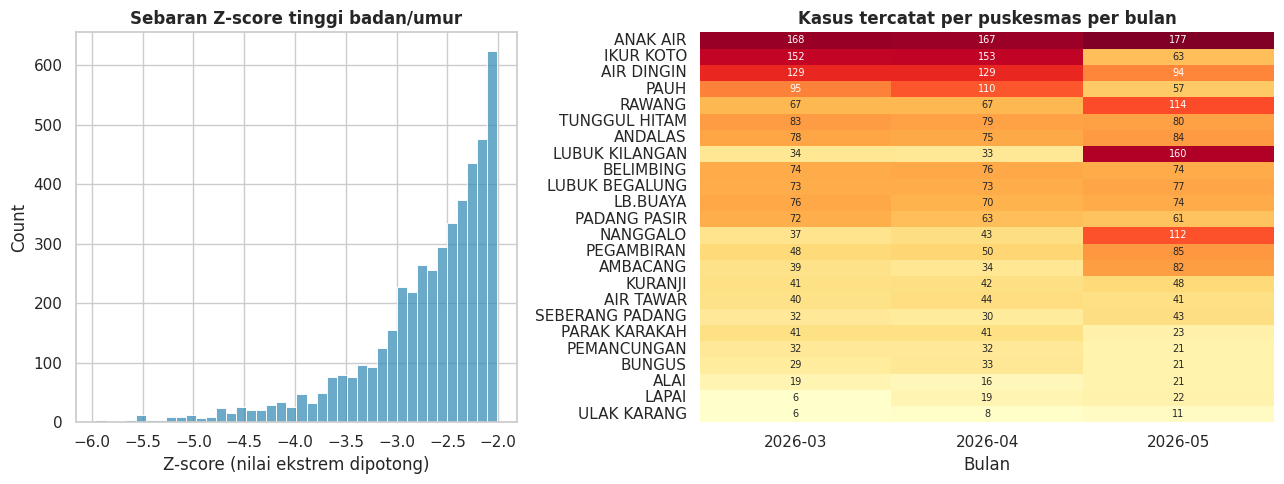

In [9]:
# Salinan khusus EDA (data asli tidak diubah)
eda = df_gabungan.copy()
for col in ['Berat', 'Tinggi', 'ZS BB/U', 'ZS TB/U', 'ZS BB/TB']:
    eda[col] = pd.to_numeric(eda[col], errors='coerce')
eda['Tgl Lahir'] = pd.to_datetime(eda['Tgl Lahir'], errors='coerce')
eda['Usia_Bulan'] = ((eda['Tanggal Pengukuran'] - eda['Tgl Lahir']).dt.days / 30.4375).round(2)
for c in ['Kec', 'Pukesmas', 'Desa/Kel']:
    eda[c] = eda[c].astype(str).str.strip().str.upper()

print(f"Baris: {len(eda)} | Puskesmas: {eda['Pukesmas'].nunique()} | Kecamatan: {eda['Kec'].nunique()} | Kelurahan: {eda['Desa/Kel'].nunique()}")

anomali = pd.Series({
    '|Z-score| > 10': int((eda[['ZS BB/U', 'ZS TB/U', 'ZS BB/TB']].abs() > 10).any(axis=1).sum()),
    'Berat > 35 kg': int((eda['Berat'] > 35).sum()),
    'Berat > 100 (kemungkinan satuan gram)': int((eda['Berat'] > 100).sum()),
    'Usia <= 0 bulan atau kosong': int(((eda['Usia_Bulan'] <= 0) | eda['Usia_Bulan'].isna()).sum()),
    'Usia > 60 bulan': int((eda['Usia_Bulan'] > 60).sum()),
}).to_frame('Jumlah baris')
print("\nBaris yang tampak tidak wajar (akan dibersihkan di Tahap 4):")
display(anomali)

pivot = eda.pivot_table(index='Pukesmas', columns='Bulan', values='Nama', aggfunc='count').fillna(0).astype(int)
pivot = pivot.loc[pivot.sum(axis=1).sort_values(ascending=False).index]
vol = pivot.sum()
print("Jumlah kasus tercatat per bulan: " + ", ".join(f"{b}: {int(v)}" for b, v in vol.items()))
rasio = (pivot.max(axis=1) / pivot.replace(0, np.nan).min(axis=1)).sort_values(ascending=False).head(3)
print("\nPuskesmas yang jumlah kasusnya paling berubah antarbulan:")
for p, r in rasio.items():
    print(f"  - {p}: {' -> '.join(str(int(x)) for x in pivot.loc[p])} (sampai {r:.1f} kali lipat)")
print("Perubahan besar bisa berarti pelaporan belum lengkap, bukan kondisi sebenarnya. Karena itu klastering memakai rata-rata 3 bulan.")

fig, ax = plt.subplots(1, 2, figsize=(13, 5), dpi=100, gridspec_kw={'width_ratios': [1, 1.3]})
sns.histplot(eda['ZS TB/U'].dropna().clip(-8, 4), bins=40, color='#3a8fb7', ax=ax[0])
ax[0].set_title('Sebaran Z-score tinggi badan/umur', fontweight='bold'); ax[0].set_xlabel('Z-score (nilai ekstrem dipotong)')
sns.heatmap(pivot, annot=True, fmt='d', cmap='YlOrRd', ax=ax[1], cbar=False, annot_kws={'size': 7})
ax[1].set_title('Kasus tercatat per puskesmas per bulan', fontweight='bold'); ax[1].set_ylabel('')
plt.tight_layout(); plt.show()

## Tahap 4 - Data Preprocessing (Membersihkan Data)

> **Penjelasan:** Membuang atau memperbaiki data yang mustahil (mis. berat 9.500 kg karena tertulis dalam gram), dan memastikan satu anak hanya terhitung sekali per bulan. Satu angka salah ketik bisa menggeser rata-rata sebuah puskesmas.


In [10]:
# ==== SEL: PEMBERSIHAN DATA ====
def bersihkan_data(df, buang_usia_60=BUANG_USIA_DI_ATAS_60_BULAN, verbose=True):
    d = df.copy()
    for col in ['Berat', 'Tinggi', 'ZS BB/U', 'ZS TB/U', 'ZS BB/TB']:
        d[col] = pd.to_numeric(d[col], errors='coerce')
    d['Tgl Lahir'] = pd.to_datetime(d['Tgl Lahir'], errors='coerce')
    d['Usia_Bulan'] = ((d['Tanggal Pengukuran'] - d['Tgl Lahir']).dt.days / 30.4375).round(2)

    jml_salah_gram = int((d['Berat'] > 100).sum())          # salah ketik gram: bagi 1000
    d.loc[d['Berat'] > 100, 'Berat'] /= 1000.0

    zs = d[['ZS BB/U', 'ZS TB/U', 'ZS BB/TB']]
    alasan = pd.DataFrame({
        'Z-score tidak wajar atau kosong': (zs.abs() > 10).any(axis=1) | zs.isna().any(axis=1),
        'Berat > 35 kg': d['Berat'] > 35,
        'Usia <= 0 atau kosong': (d['Usia_Bulan'] <= 0) | d['Usia_Bulan'].isna(),
        'Usia > 60 bulan (di luar balita)': (d['Usia_Bulan'] > 60) if buang_usia_60 else False,
    })
    mask = alasan.any(axis=1)
    if verbose:
        print("Baris yang dibuang menurut alasan (satu baris bisa kena lebih dari satu alasan):")
        print(alasan.sum().to_string())
    d = d[~mask].copy()
    if verbose:
        print(f"Berat dikoreksi dari gram: {jml_salah_gram} baris | Dibuang: {int(mask.sum())} baris | Sisa valid: {len(d)} baris")

    for c in ['Kec', 'Pukesmas', 'Desa/Kel']:
        d[c] = d[c].astype(str).str.strip().str.upper()
    # Kunci anak = nama + tanggal lahir (NIK tidak dipakai: banyak yang tidak valid dan berubah antarbulan)
    d['Kunci_Anak'] = d['Nama'].astype(str).str.strip().str.upper() + "_" + d['Tgl Lahir'].dt.strftime('%Y-%m-%d')
    n0 = len(d)
    d = d.sort_values('Tanggal Pengukuran').drop_duplicates(['Bulan', 'Kunci_Anak'], keep='last')
    if verbose:
        print(f"Duplikat anak dalam bulan yang sama dibuang: {n0 - len(d)} baris")
        print(f"Total baris akhir: {len(d)} | Anak unik lintas bulan: {d['Kunci_Anak'].nunique()}")
    return d

df_bersih = bersihkan_data(df_gabungan)

Baris yang dibuang menurut alasan (satu baris bisa kena lebih dari satu alasan):
Z-score tidak wajar atau kosong     37
Berat > 35 kg                        2
Usia <= 0 atau kosong               91
Usia > 60 bulan (di luar balita)    33
Berat dikoreksi dari gram: 4 baris | Dibuang: 130 baris | Sisa valid: 4473 baris
Duplikat anak dalam bulan yang sama dibuang: 2 baris
Total baris akhir: 4471 | Anak unik lintas bulan: 2417


## Tahap 5 - Feature Engineering & Selection (Membuat Indikator per Puskesmas)

> **Penjelasan:** Ribuan baris anak diringkas menjadi 24 baris (satu per puskesmas), masing-masing dengan 5 indikator. Model membandingkan puskesmas, bukan anak.
>
> **Standardisasi:** Menyamakan skala agar indikator angka besar tidak mendominasi

| Indikator | Cara hitung | Mewakili |
|---|---|---|
| `Kasus per sasaran balita` | kasus tercatat / (sasaran balita x jumlah bulan) x 100 | Beban kasus (juga gambaran beban pelayanan terhadap jumlah balita) |
| `Persen sangat pendek` | balita sangat pendek / kasus x 100 | Keparahan stunting |
| `Persen stunting + kurus` | gizi kurang atau buruk / kasus x 100 | Beban ganda stunting dan kurus |
| `Persen berat tidak naik` | berat badan tidak naik / kasus x 100 | Pertumbuhan mandek (pola asuh dan makan) |
| `Persen bumil KEK` | % ibu hamil KEK (rekap Dinkes) | Risiko dari sisi gizi ibu |
>
> **Indikator pembentuk kelompok vs indikator profil:** Semua 5 indikator dipakai untuk *skor urgensi*, peringkat, dan profil kelompok. Namun kelompok dibentuk dari 2 indikator inti saja, yaitu **Kasus per sasaran balita** (beban kasus) dan **Persen berat tidak naik** (pertumbuhan mandek). Pada uji kombinasi fitur, hanya pasangan ini yang menghasilkan Silhouette >= 0,5 dengan K=3. Tiga indikator lain (sangat pendek, stunting + kurus, bumil KEK) berbaur di antara kelompok sehingga menurunkan Silhouette bila ikut dipakai membentuk kelompok.


In [11]:
# ==== SEL: DATA REFERENSI DINKES + (OPSIONAL) VARIABEL PENYEBAB ====
sasaran_dict = {
    'IKUR KOTO': 1194, 'ANAK AIR': 2106, 'RAWANG': 1186, 'AIR TAWAR': 651,
    'SEBERANG PADANG': 643, 'PADANG PASIR': 1446, 'NANGGALO': 1740, 'LUBUK KILANGAN': 4276,
    'BUNGUS': 1872, 'ALAI': 2107, 'AIR DINGIN': 3234, 'TUNGGUL HITAM': 2423,
    'PAUH': 3136, 'PARAK KARAKAH': 1398, 'ANDALAS': 3261, 'PEMANCUNGAN': 1237,
    'AMBACANG': 2345, 'BELIMBING': 3653, 'KURANJI': 2126, 'LUBUK BEGALUNG': 4483,
    'LAPAI': 986, 'LB.BUAYA': 5818, 'PEGAMBIRAN': 5251, 'ULAK KARANG': 934
}
bumil_kek_dict = {
    'IKUR KOTO': 15.7, 'ANAK AIR': 11.6, 'RAWANG': 12.0, 'AIR TAWAR': 9.9,
    'SEBERANG PADANG': 16.4, 'PADANG PASIR': 12.2, 'NANGGALO': 11.7, 'LUBUK KILANGAN': 11.7,
    'BUNGUS': 16.2, 'ALAI': 25.4, 'AIR DINGIN': 9.6, 'TUNGGUL HITAM': 7.2,
    'PAUH': 13.4, 'PARAK KARAKAH': 10.6, 'ANDALAS': 11.3, 'PEMANCUNGAN': 10.4,
    'AMBACANG': 10.7, 'BELIMBING': 10.2, 'KURANJI': 10.9, 'LUBUK BEGALUNG': 9.2,
    'LAPAI': 8.5, 'LB.BUAYA': 2.9, 'PEGAMBIRAN': 11.2, 'ULAK KARANG': 9.7
}
tak_cocok = set(df_bersih['Pukesmas']) - set(sasaran_dict)
assert not tak_cocok, f"Nama puskesmas tidak cocok dengan kamus sasaran: {tak_cocok}"
print(f"Puskesmas terdeteksi: {df_bersih['Pukesmas'].nunique()} (harus 24)")

# Templat file variabel penyebab (kolom kosong; isi dengan data resmi Dinkes/BPS, SEMUA kolom dibaca makin tinggi = makin buruk)
KOLOM_PENYEBAB_CONTOH = ['Persen rumah tanpa sanitasi layak', 'Persen rumah tanpa air minum layak', 'Persen penduduk miskin',
                         'Persen bayi tanpa ASI eksklusif', 'Persen ibu berpendidikan rendah', 'Balita per puskesmas']
pd.DataFrame({'Puskesmas': list(sasaran_dict), **{c: np.nan for c in KOLOM_PENYEBAB_CONTOH}}).to_excel(
    'Template_Variabel_Penyebab.xlsx', index=False)

FILE_PENYEBAB = 'Variabel_Penyebab_Puskesmas.xlsx'
penyebab_dict = {}          # {nama kolom: {puskesmas: nilai}}
if os.path.exists(FILE_PENYEBAB):
    try:
        dfp = pd.read_excel(FILE_PENYEBAB)
        dfp['Puskesmas'] = dfp['Puskesmas'].astype(str).str.strip().str.upper()
        dfp = dfp.drop_duplicates('Puskesmas').set_index('Puskesmas')
        kolom = [c for c in dfp.columns if not str(c).startswith('Unnamed')]
        for c in kolom:
            dfp[c] = pd.to_numeric(dfp[c], errors='coerce')
        lengkap = (len(kolom) > 0 and set(sasaran_dict) <= set(dfp.index)
                   and not dfp.loc[list(sasaran_dict), kolom].isna().any().any())
        if lengkap:
            penyebab_dict = {c: dfp[c].to_dict() for c in kolom}
            print(f"Variabel penyebab dimuat dan dipakai sebagai fitur: {kolom}")
        else:
            print("PERINGATAN: file variabel penyebab tidak lengkap (harus ada 24 puskesmas dan semua sel terisi angka). File DIABAIKAN.")
    except Exception as e:
        print("PERINGATAN: file variabel penyebab gagal dibaca, DIABAIKAN:", e)
else:
    print("Info: file opsional variabel penyebab tidak ditemukan. Model memakai 5 indikator BNBA + Dinkes.")
    print("      Templat kosong tersimpan: Template_Variabel_Penyebab.xlsx")

fitur_dasar = ['Kasus per sasaran balita', 'Persen sangat pendek', 'Persen stunting + kurus',
               'Persen berat tidak naik', 'Persen bumil KEK']
fitur_klaster = fitur_dasar + list(penyebab_dict)
print(f"Jumlah indikator (skor urgensi + profil): {len(fitur_klaster)} -> {fitur_klaster}")
# Indikator inti: dua indikator yang membentuk kelompok (beban kasus dan pertumbuhan mandek)
fitur_inti = ['Kasus per sasaran balita', 'Persen berat tidak naik']
print(f"Indikator pembentuk kelompok: {fitur_inti}")

Puskesmas terdeteksi: 24 (harus 24)
Info: file opsional variabel penyebab tidak ditemukan. Model memakai 5 indikator BNBA + Dinkes.
      Templat kosong tersimpan: Template_Variabel_Penyebab.xlsx
Jumlah fitur klaster: 5 -> ['Kasus per sasaran balita', 'Persen sangat pendek', 'Persen stunting + kurus', 'Persen berat tidak naik', 'Persen bumil KEK']


=== 24 PUSKESMAS KOTA PADANG (indikator utama) ===


,Puskesmas,Kecamatan,Rerata_kasus_per_bulan,Sasaran_balita_per_bulan,Kasus per sasaran balita,Persen sangat pendek,Persen stunting + kurus,Persen berat tidak naik,Persen bumil KEK
8,IKUR KOTO,KOTO TANGAH,122.0,1194,10.22,14.8,12.6,47.8,15.7
4,ANAK AIR,KOTO TANGAH,166.0,2106,7.88,27.5,19.7,42.4,11.6
20,RAWANG,PADANG SELATAN,81.3,1186,6.86,22.1,11.1,45.9,12.0
1,AIR TAWAR,PADANG UTARA,41.7,651,6.40,21.6,23.2,47.2,9.9
21,SEBERANG PADANG,PADANG SELATAN,34.7,643,5.39,12.5,27.9,43.3,16.4
15,PADANG PASIR,PADANG BARAT,63.7,1446,4.40,24.1,11.0,49.7,12.2
0,AIR DINGIN,KOTO TANGAH,114.7,3234,3.55,23.5,13.1,38.1,9.6
22,TUNGGUL HITAM,KOTO TANGAH,80.7,2423,3.33,28.9,9.5,26.0,7.2
14,NANGGALO,NANGGALO,54.3,1740,3.12,47.9,7.4,55.2,11.7
17,PAUH,PAUH,85.3,3136,2.72,23.0,10.9,39.1,13.4


Puskesmas dengan kasus tercatat < 30 per bulan (persentasenya mudah naik-turun karena angka kecil): ALAI, BUNGUS, LAPAI, PEMANCUNGAN, ULAK KARANG


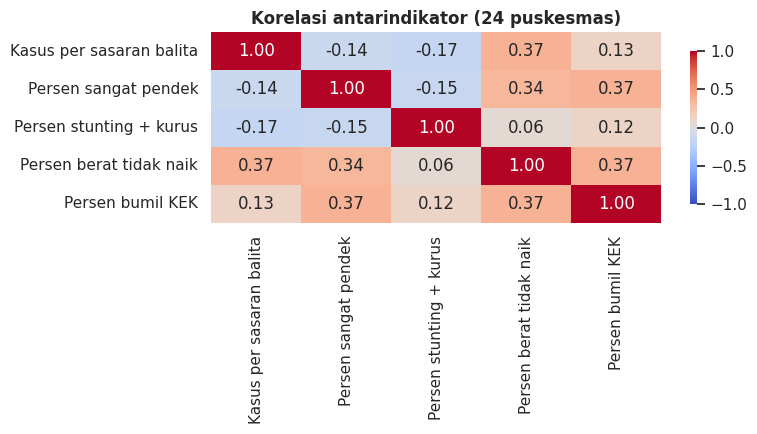

Pasangan indikator yang sangat berkaitan (|r| >= 0,7): tidak ada, jadi tiap indikator membawa informasi berbeda.


In [12]:
# ==== SEL: MENGHITUNG INDIKATOR PER PUSKESMAS ====
def hitung_fitur(grp, jml_bulan):
    out = grp.agg(
        Jml_kelurahan=('Desa/Kel', 'nunique'),
        Total_Kasus=('Kunci_Anak', 'count'),
        Total_SP=('TB/U', lambda s: (s.astype(str).str.strip() == 'Sangat Pendek').sum()),
        Total_SW=('BB/TB', lambda s: s.astype(str).str.strip().isin(['Gizi Kurang', 'Gizi Buruk']).sum()),
        Total_BBT=('Naik Berat Badan', lambda s: (s.astype(str).str.strip() == 'T').sum()),
    ).reset_index().rename(columns={'Kec': 'Kecamatan', 'Pukesmas': 'Puskesmas'})
    out['Rerata_kasus_per_bulan'] = (out['Total_Kasus'] / jml_bulan).round(1)
    out['Sasaran_balita_per_bulan'] = out['Puskesmas'].map(sasaran_dict)
    out['Kasus per sasaran balita'] = (out['Total_Kasus'] / (out['Sasaran_balita_per_bulan'] * jml_bulan) * 100).round(2)
    out['Persen sangat pendek'] = (out['Total_SP'] / out['Total_Kasus'] * 100).round(1)
    out['Persen stunting + kurus'] = (out['Total_SW'] / out['Total_Kasus'] * 100).round(1)
    out['Persen berat tidak naik'] = (out['Total_BBT'] / out['Total_Kasus'] * 100).round(1)
    out['Persen bumil KEK'] = out['Puskesmas'].map(bumil_kek_dict)
    for c, dct in penyebab_dict.items():
        out[c] = out['Puskesmas'].map(dct)
    return out

# Per puskesmas per bulan (dipakai pemantauan Tahap 12)
agg_bulanan = pd.concat(
    [hitung_fitur(sub.groupby(['Kec', 'Pukesmas']), 1).assign(Bulan=bln) for bln, sub in df_bersih.groupby('Bulan')],
    ignore_index=True)

# Gabungan 3 bulan per puskesmas = dasar pemodelan (24 baris)
df_puskesmas = hitung_fitur(df_bersih.groupby(['Kec', 'Pukesmas']), 3).sort_values('Puskesmas').reset_index(drop=True)
assert df_puskesmas['Puskesmas'].nunique() == 24, f"Puskesmas terdeteksi {df_puskesmas['Puskesmas'].nunique()}, seharusnya 24"
df_puskesmas['Data_Sedikit'] = df_puskesmas['Rerata_kasus_per_bulan'] < BATAS_KASUS_SEDIKIT

# Standardisasi (StandardScaler: rata-rata 0, simpangan baku 1)
X = df_puskesmas[fitur_klaster].copy()           # semua indikator (skor urgensi + profil)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X[fitur_inti])   # ruang klaster: hanya 2 indikator inti

print("=== 24 PUSKESMAS KOTA PADANG (indikator utama) ===")
display(df_puskesmas.sort_values('Kasus per sasaran balita', ascending=False)[
    ['Puskesmas', 'Kecamatan', 'Rerata_kasus_per_bulan', 'Sasaran_balita_per_bulan'] + fitur_klaster])
sedikit = df_puskesmas.loc[df_puskesmas['Data_Sedikit'], 'Puskesmas'].tolist()
print(f"Puskesmas dengan kasus tercatat < {BATAS_KASUS_SEDIKIT} per bulan (persentasenya mudah naik-turun karena angka kecil): {', '.join(sedikit) if sedikit else 'tidak ada'}")

# Cek keterkaitan antarindikator
korelasi = df_puskesmas[fitur_klaster].corr().round(2)
plt.figure(figsize=(6 + 0.4 * len(fitur_klaster), 4.5), dpi=100)
sns.heatmap(korelasi, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f', cbar_kws={'shrink': 0.8})
plt.title('Korelasi antarindikator (24 puskesmas)', fontweight='bold'); plt.tight_layout(); plt.show()
kuat = [(a, b, korelasi.loc[a, b]) for i, a in enumerate(fitur_klaster) for b in fitur_klaster[i+1:] if abs(korelasi.loc[a, b]) >= 0.7]
print("Pasangan indikator yang sangat berkaitan (|r| >= 0,7):", kuat if kuat else "tidak ada, jadi tiap indikator membawa informasi berbeda.")

## Tahap 6 - Data Splitting (Membagi Data) | Metrik 3: ARI antarperiode

> **Penjelasan:** Melompokkan puskesmas dengan data Maret–April dan Mei secara terpisah, lalu mengukur kemiripannya dengan **ARI**.
>
> **Cara membaca ARI:** 1 = identik, 0 = tidak mirip sama sekali. 0,7 atau lebih baik; 0,5–0,7 sedang; di bawah 0,5 rendah. ARI rendah bukan berarti model salah; artinya pengelompokan dari satu atau dua bulan saja belum stabil, jadi keputusan kebijakan memakai rata-rata 3 bulan.

In [ ]:
# ==== METRIK 3: ARI ANTARPERIODE (Maret-April vs Mei) ====
df_latih = hitung_fitur(df_bersih[df_bersih['Bulan'].isin(BULAN_LATIH)].groupby(['Kec', 'Pukesmas']), len(BULAN_LATIH)).sort_values('Puskesmas').reset_index(drop=True)
df_uji = hitung_fitur(df_bersih[df_bersih['Bulan'] == BULAN_UJI].groupby(['Kec', 'Pukesmas']), 1).sort_values('Puskesmas').reset_index(drop=True)
assert list(df_latih['Puskesmas']) == list(df_uji['Puskesmas']), "Daftar puskesmas data latih dan data uji harus sama"

lab_latih = kmeans_init_ward(StandardScaler().fit_transform(df_latih[fitur_inti]), K).labels_
lab_uji = kmeans_init_ward(StandardScaler().fit_transform(df_uji[fitur_inti]), K).labels_
ari_antarperiode = adjusted_rand_score(lab_latih, lab_uji)

def nilai_ari(v):
    return 'Baik' if v >= 0.7 else ('Sedang' if v >= 0.5 else 'Rendah')

print("=== METRIK 3: ARI ANTARPERIODE ===")
print(f"Kelompok dari Maret-April: ukuran {sorted(np.bincount(lab_latih).tolist(), reverse=True)} | dari Mei: ukuran {sorted(np.bincount(lab_uji).tolist(), reverse=True)}")
print(f"ARI = {ari_antarperiode:.2f} -> {nilai_ari(ari_antarperiode)}")
if ari_antarperiode < 0.5:
    print("Artinya: pengelompokan dari bulan yang berbeda belum mirip. Gunakan rata-rata 3 bulan untuk keputusan, dan jangan membaca perpindahan kelompok antarbulan sebagai perubahan nyata.")
else:
    print("Artinya: pola kelompok cukup konsisten antarperiode.")

## Tahap 7 - Model Selection (Memilih Algoritma) | Metrik 1: Silhouette

> **Penjelasan:** Mencoba dua cara mengelompokkan (K-Means dan Hierarchical Ward) lalu membandingkan skor **Silhouette**-nya. Silhouette makin tinggi = kelompok makin jelas terpisah.


In [ ]:
# ==== METRIK 1: SILHOUETTE UNTUK MEMBANDINGKAN ALGORITMA ====
lab_km = KMeans(K, n_init=N_INIT, random_state=SEED).fit_predict(X_scaled)
lab_ward = AgglomerativeClustering(K, linkage='ward').fit_predict(X_scaled)
lab_kmw = kmeans_init_ward(X_scaled, K).labels_

baris = []
for nama, lab in [('K-Means (titik awal acak)', lab_km), ('Hierarchical (Ward)', lab_ward), ('K-Means (titik awal Ward)', lab_kmw)]:
    ukuran = sorted(np.bincount(lab).tolist(), reverse=True)
    baris.append({'Algoritma': nama, 'Silhouette': round(silhouette_score(X_scaled, lab), 3),
                  'Ukuran kelompok': ukuran, 'Memenuhi syarat (min 3)': min(ukuran) >= 3})
tabel_model = pd.DataFrame(baris)
print("=== PERBANDINGAN ALGORITMA (K=3, indikator inti) ===")
display(tabel_model)

pilih = tabel_model.iloc[2]
print(f"Keputusan: K-Means dengan titik awal dari Ward dipakai (Silhouette {pilih['Silhouette']}). "
      "Hasilnya sama dengan Ward, tetapi punya pusat kelompok sehingga bisa memprediksi puskesmas/bulan baru.")


## Tahap 8 - Model Training (Melatih Model, Memberi Profil dan Usulan)

> **Penjelasan:** K-Means membagi 24 puskesmas menjadi 3 kelompok. Setelah kelompok terbentuk (tanpa label apa pun), kita:
> 1. **Mengurutkan** kelompok memakai *skor urgensi* = rata-rata z-score semua indikator (bobot sama). Skor tertinggi = **Prioritas 1**.
> 2. **Membuat profil**: indikator mana yang menonjol tinggi atau rendah pada tiap kelompok.
> 3. **Menyusun usulan tindakan** langsung dari indikator yang menonjol, jadi tiap kelompok mendapat fokus intervensi berbeda (tidak dibagi rata).


In [15]:
# ==== SEL: ATURAN PENAMAAN, PROFIL, DAN USULAN ====
AKSI = {   # indikator menonjol -> fokus tindakan
    'Kasus per sasaran balita': 'percepat penjangkauan dan penimbangan di posyandu, pastikan PMT lokal menjangkau semua kasus tercatat',
    'Persen sangat pendek': 'rujuk balita sangat pendek ke dokter/ahli gizi dan pantau tinggi badan tiap bulan',
    'Persen stunting + kurus': 'perkuat tata laksana gizi kurang/buruk (PMT pemulihan, cek penyakit penyerta)',
    'Persen berat tidak naik': 'lakukan kunjungan rumah dan konseling pola makan/MP-ASI bagi balita yang berat badannya tidak naik',
    'Persen bumil KEK': 'perkuat gizi ibu hamil (PMT bumil, pemeriksaan kehamilan, tablet tambah darah)',
    'Persen rumah tanpa sanitasi layak': 'fokus infrastruktur sanitasi (jamban sehat) dan perilaku hidup bersih',
    'Persen rumah tanpa air minum layak': 'fokus infrastruktur air minum layak dan pengolahan air rumah tangga',
    'Persen penduduk miskin': 'fokus subsidi/bantuan pangan bergizi bagi keluarga miskin',
    'Persen bayi tanpa ASI eksklusif': 'perkuat konseling ASI eksklusif dan kelas ibu menyusui',
    'Persen ibu berpendidikan rendah': 'perkuat edukasi gizi dan pengasuhan untuk ibu',
    'Balita per puskesmas': 'tambah tenaga gizi atau pos pelayanan karena beban balita per puskesmas tinggi',
}

def zscore(df, fts=None):
    fts = fts or fitur_klaster
    return (df[fts] - df[fts].mean()) / df[fts].std(ddof=0)

def centroid_z(df, label, fts=None):
    return zscore(df, fts).reset_index(drop=True).groupby(np.asarray(label)).mean()

def beri_nama_prioritas(cz):
    """Skor urgensi klaster = rata-rata z-score; skor tertinggi = Prioritas 1."""
    urut = cz.mean(axis=1).sort_values(ascending=False).index
    return {int(c): f"Prioritas {i + 1}" for i, c in enumerate(urut)}

def ciri_klaster(baris_z, batas=0.5):
    tinggi = [f"{f} ({v:+.1f} SD)" for f, v in baris_z.sort_values(ascending=False).items() if v >= batas]
    rendah = [f"{f} ({v:+.1f} SD)" for f, v in baris_z.sort_values().items() if v <= -batas]
    teks = "Tinggi: " + (", ".join(tinggi) if tinggi else "tidak ada")
    return teks + " | Rendah: " + (", ".join(rendah) if rendah else "tidak ada")

def buat_usulan(baris_z, batas=0.5):
    dominan = [f for f, v in baris_z.sort_values(ascending=False).items() if v >= batas][:3]
    if not dominan:
        return "Pemantauan rutin bulanan di posyandu serta edukasi gizi dan sanitasi keluarga."
    usulan = "Fokus: " + "; ".join(AKSI.get(f, f"tangani faktor '{f}'") for f in dominan) + "."
    if baris_z['Kasus per sasaran balita'] <= -0.3 and baris_z['Persen sangat pendek'] >= batas:
        usulan += " Catatan: kasus tercatat sedikit tetapi berat, jadi verifikasi dulu kelengkapan pelaporan posyandu."
    return usulan
print("Fungsi penamaan, profil, dan usulan siap.")

Fungsi penamaan, profil, dan usulan siap.


In [ ]:
# ==== SEL: MELATIH MODEL FINAL DAN MEMBUAT PROFIL ====
kmeans_model = kmeans_init_ward(X_scaled, K)      # dilatih pada 2 indikator inti
df_puskesmas['Cluster_ID'] = kmeans_model.labels_

cz = centroid_z(df_puskesmas, df_puskesmas['Cluster_ID'])
peta_prioritas = beri_nama_prioritas(cz)
df_puskesmas['Kelompok_Prioritas'] = df_puskesmas['Cluster_ID'].map(peta_prioritas)
skor_mentah = zscore(df_puskesmas).mean(axis=1)      # hanya untuk peringkat; BUKAN dipakai membentuk kelompok
df_puskesmas['Skor_Urgensi'] = skor_mentah.round(2)
df_puskesmas['Peringkat_Kota'] = skor_mentah.rank(ascending=False, method='first').astype(int)

urutan_nama = [peta_prioritas[c] for c in cz.mean(axis=1).sort_values(ascending=False).index]
REKOMENDASI = {peta_prioritas[c]: buat_usulan(cz.loc[c]) for c in cz.index}
CIRI = {peta_prioritas[c]: ciri_klaster(cz.loc[c]) for c in cz.index}
df_puskesmas['Ciri_Kelompok'] = df_puskesmas['Kelompok_Prioritas'].map(CIRI)
df_puskesmas['Usulan_Kebijakan'] = df_puskesmas['Kelompok_Prioritas'].map(REKOMENDASI)

print("=== PROFIL KELOMPOK: nilai rata-rata asli tiap indikator ===")
profil = df_puskesmas.groupby('Kelompok_Prioritas')[fitur_klaster].mean().round(2)
profil.insert(0, 'Jml_Puskesmas', df_puskesmas.groupby('Kelompok_Prioritas').size())
display(profil.loc[urutan_nama])

print("\n=== PUSAT KELOMPOK DALAM z-score (positif = di atas rata-rata kota = lebih buruk) ===")
tabel_z = cz.round(2).copy(); tabel_z.index = [peta_prioritas[c] for c in tabel_z.index]
tabel_z['Skor_Urgensi_Kelompok'] = tabel_z.mean(axis=1).round(2)
display(tabel_z.loc[urutan_nama])

for nama in urutan_nama:
    anggota = df_puskesmas.loc[df_puskesmas['Kelompok_Prioritas'] == nama, 'Puskesmas'].tolist()
    print(f"\n{nama} ({len(anggota)} puskesmas): {', '.join(anggota)}")
    print(f"  Ciri dominan : {CIRI[nama]}")
    print(f"  Usulan       : {REKOMENDASI[nama]}")

## Tahap 9 - Hyperparameter Tuning (Memilih Jumlah Kelompok K) | Metrik 1 dan 2

> **Penjelasan:** Menguji apakah 3 kelompok masuk akal dibanding 2 atau 4 kelompok, memakai dua metrik:
> - **Silhouette** (makin tinggi makin baik).
> - **Elbow / Inertia** (jarak puskesmas ke pusat kelompoknya, makin kecil makin rapat). Inertia pasti turun saat K naik, jadi yang dicari adalah siku, yaitu titik setelah itu penurunannya melandai.
>
> K=3 ditetapkan sejak awal karena kebutuhan kebijakan (tiga tingkat prioritas)

In [ ]:
# ==== METRIK 1 + 2: SILHOUETTE DAN ELBOW UNTUK K = 2, 3, 4 ====
baris_k = []
for k in [2, 3, 4]:
    km_k = kmeans_init_ward(X_scaled, k)
    ukuran = sorted(np.bincount(km_k.labels_).tolist(), reverse=True)
    baris_k.append({'K': k, 'Silhouette': round(silhouette_score(X_scaled, km_k.labels_), 3),
                    'Inertia': round(km_k.inertia_, 2), 'Kelompok terkecil': min(ukuran), 'Ukuran kelompok': ukuran})
tabel_k = pd.DataFrame(baris_k)
display(tabel_k)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), dpi=100)
ax[0].plot(tabel_k['K'], tabel_k['Inertia'], marker='o', color='#1f3a5f', linewidth=2)
ax[0].set_title('Metrik 2 - Elbow (Inertia)', fontweight='bold'); ax[0].set_xlabel('K'); ax[0].set_xticks([2, 3, 4])
ax[1].plot(tabel_k['K'], tabel_k['Silhouette'], marker='s', color='#e8a33d', linewidth=2)
ax[1].axvline(3, ls=':', color='green', label='K=3 dipakai'); ax[1].legend()
ax[1].set_title('Metrik 1 - Silhouette', fontweight='bold'); ax[1].set_xlabel('K'); ax[1].set_xticks([2, 3, 4])
plt.tight_layout(); plt.show()

turun_23 = tabel_k.loc[0, 'Inertia'] - tabel_k.loc[1, 'Inertia']
turun_34 = tabel_k.loc[1, 'Inertia'] - tabel_k.loc[2, 'Inertia']
valid = tabel_k[tabel_k['Kelompok terkecil'] >= 3].sort_values('Silhouette', ascending=False)
k_terbaik = int(valid.iloc[0]['K']) if len(valid) else 3
siku = "ada siku ringan di K=3" if turun_23 >= 1.5 * turun_34 else "tidak ada siku yang tajam"
print(f"Elbow: inertia turun {turun_23:.1f} dari K=2 ke K=3, lalu {turun_34:.1f} dari K=3 ke K=4 -> {siku}.")
print(f"Silhouette: K=2 {tabel_k.loc[0, 'Silhouette']}, K=3 {tabel_k.loc[1, 'Silhouette']}, K=4 {tabel_k.loc[2, 'Silhouette']}. "
      f"K=4 {'melanggar' if tabel_k.loc[2, 'Kelompok terkecil'] < 3 else 'memenuhi'} syarat minimal 3 puskesmas per kelompok.")
if k_terbaik == 3:
    print("Keputusan: K=3 didukung data (Silhouette tertinggi di antara K yang memenuhi syarat) dan sesuai kebutuhan tiga tingkat prioritas.")
else:
    print(f"PERHATIAN: data sedikit lebih mendukung K={k_terbaik}. K=3 tetap dipakai karena kebutuhan tiga tingkat prioritas Dinkes; laporkan selisih ini apa adanya.")

## Tahap 10 - Model Evaluation (Menilai Hasil)

> **Penjelasan:** Mutu hasil dinilai dengan 4 metrik. Dua metrik sudah dihitung (Metrik 2 di Tahap 9, Metrik 3 di Tahap 6). Di sini ditambah Silhouette model final dan Bootstrap, lalu semuanya dirangkum di kartu skor.
>
> **Bootstrap (Metrik 4):** Sampel anak di tiap puskesmas diambil ulang secara acak 300 kali, lalu dicek apakah puskesmas itu tetap masuk kelompok yang sama. Bila ya di 70% pengulangan atau lebih dan silhouette puskesmas itu tidak negatif, keanggotaannya berstatus Pasti.


In [ ]:
# ==== METRIK 1: SILHOUETTE MODEL FINAL ====
lab_final = df_puskesmas['Cluster_ID'].to_numpy()
sil_final = silhouette_score(X_scaled, lab_final)

def nilai_sil(v):   # Kaufman & Rousseeuw: >0,70 kuat | 0,51-0,70 cukup | 0,26-0,50 lemah | <=0,25 tidak ada struktur
    return 'Kuat' if v > 0.7 else ('Cukup' if v >= 0.5 else ('Lemah' if v > 0.25 else 'Tidak ada struktur'))

print("=== METRIK 1: SILHOUETTE MODEL FINAL ===")
print(f"Silhouette = {sil_final:.3f} -> {nilai_sil(sil_final)}")
print("Artinya: " + ("kelompok cukup terpisah pada dua indikator inti (beban kasus dan pertumbuhan mandek)." if sil_final >= 0.5 else
      "kelompok saling tumpang tindih. Wajar pada 24 puskesmas, tetapi hasil lebih tepat disebut pemeringkatan profil prioritas daripada kelompok alami yang tegas."))
print("Catatan: skor dihitung pada 2 indikator inti, bukan 5. Tiga indikator lain dipakai untuk profil dan skor urgensi.")


In [ ]:
# ==== METRIK 4: BOOTSTRAP KEANGGOTAAN (300 pengulangan) ====
rng = np.random.default_rng(SEED)
daftar_pusk = df_puskesmas['Puskesmas'].tolist()

d = df_bersih[['Pukesmas', 'TB/U', 'BB/TB', 'Naik Berat Badan']].copy()
d['k'] = 1
d['sp'] = (d['TB/U'].astype(str).str.strip() == 'Sangat Pendek').astype(int)
d['sw'] = d['BB/TB'].astype(str).str.strip().isin(['Gizi Kurang', 'Gizi Buruk']).astype(int)
d['bbt'] = (d['Naik Berat Badan'].astype(str).str.strip() == 'T').astype(int)
arr_pusk = {p: g[['k', 'sp', 'sw', 'bbt']].to_numpy() for p, g in d.groupby('Pukesmas')}

def fitur_dari(data_per_pusk):
    baris = []
    for p in daftar_pusk:
        a = data_per_pusk[p]; n = a[:, 0].sum()
        baris.append([n / (sasaran_dict[p] * 3) * 100, a[:, 1].sum() / n * 100, a[:, 2].sum() / n * 100,
                      a[:, 3].sum() / n * 100, bumil_kek_dict[p]] + [penyebab_dict[c][p] for c in penyebab_dict])
    return pd.DataFrame(baris, columns=fitur_klaster)

def ambil_ulang(arr):
    out = {}
    for p, a in arr.items():
        n_baru = max(int(rng.poisson(len(a))), 2)
        out[p] = a[rng.integers(0, len(a), n_baru)]
    return out

hitung_sama = np.zeros(len(daftar_pusk))
for _ in range(BOOTSTRAP):
    Xb = fitur_dari(ambil_ulang(arr_pusk))
    hitung_sama += (kmeans_model.predict(scaler.transform(Xb[fitur_inti])) == lab_final)

df_puskesmas['Keyakinan_(%)'] = (hitung_sama / BOOTSTRAP * 100).round(1)
df_puskesmas['Silhouette_Puskesmas'] = silhouette_samples(X_scaled, lab_final).round(3)
df_puskesmas['Status_Kepastian'] = np.where(
    (df_puskesmas['Keyakinan_(%)'] >= BATAS_PASTI) & (df_puskesmas['Silhouette_Puskesmas'] >= 0), 'Pasti', 'Belum pasti')
rerata_yakin = float(df_puskesmas['Keyakinan_(%)'].mean())
n_pasti = int((df_puskesmas['Status_Kepastian'] == 'Pasti').sum())
n_belum = len(df_puskesmas) - n_pasti

print("=== METRIK 4: BOOTSTRAP KEANGGOTAAN ===")
print(f"Rata-rata puskesmas tetap sekelompok: {rerata_yakin:.0f}% dari {BOOTSTRAP} pengulangan")
print(f"Status: {n_pasti} puskesmas Pasti | {n_belum} puskesmas Belum pasti")
if n_belum:
    display(df_puskesmas.loc[df_puskesmas['Status_Kepastian'] == 'Belum pasti', ['Puskesmas', 'Kelompok_Prioritas', 'Keyakinan_(%)', 'Silhouette_Puskesmas']])
    print("Puskesmas 'Belum pasti' berada di perbatasan kelompok (bootstrap rendah atau silhouette negatif); sebaiknya ditinjau langsung oleh Dinkes.")

In [ ]:
# ==== KARTU SKOR: 4 METRIK DALAM SATU TABEL ====
akhir_elbow = ('ada siku ringan di K=3' if turun_23 >= 1.5 * turun_34 else 'tidak ada siku tajam; K=3 dipilih karena kebutuhan kebijakan')
kartu = pd.DataFrame([
    ['1. Silhouette',            'Seberapa jelas kelompok terpisah?',            f"{sil_final:.3f}",                              nilai_sil(sil_final)],
    ['2. Elbow (Inertia)',       'Apakah K=3 cukup?',                            f"{turun_23:.1f} (K2-3) vs {turun_34:.1f} (K3-4)", akhir_elbow],
    ['3. ARI antarperiode',      'Apakah pola sama di bulan berbeda?',           f"{ari_antarperiode:.2f}",                       nilai_ari(ari_antarperiode)],
    ['4. Bootstrap keanggotaan', 'Apakah puskesmas tetap di kelompoknya?',       f"{rerata_yakin:.0f}% | Pasti {n_pasti}/{len(df_puskesmas)}", 'Baik' if n_belum <= len(df_puskesmas) * 0.10 else ('Sedang' if n_belum <= len(df_puskesmas) * 0.25 else 'Rendah')],
], columns=['Metrik', 'Pertanyaan', 'Hasil', 'Penilaian'])
print("=== KARTU SKOR EVALUASI MODEL ===")
display(kartu)

print("\nKESIMPULAN (ditulis otomatis dari angka di atas)")
print(f"- Kelompok terpisah {nilai_sil(sil_final).lower()} (Silhouette {sil_final:.2f}); K=3 {'didukung' if k_terbaik == 3 else 'kurang didukung'} oleh data.")
print(f"- Kemiripan pola antarperiode {nilai_ari(ari_antarperiode).lower()} (ARI {ari_antarperiode:.2f}), jadi keputusan memakai rata-rata 3 bulan.")
print(f"- {n_pasti} dari {len(df_puskesmas)} puskesmas keanggotaannya pasti; {n_belum} belum pasti.")
if sil_final < 0.5 or ari_antarperiode < 0.5:
    print("CARA MENYEBUT HASIL: 'pemeringkatan profil prioritas berdasarkan indikator stunting' yang perlu divalidasi Dinkes, "
          "BUKAN 'ditemukan 3 kelompok alami' dan BUKAN klasifikasi pasti.")
else:
    print("CARA MENYEBUT HASIL: alat bantu prioritas yang tetap perlu divalidasi Dinkes sebelum dipakai untuk anggaran.")

### Hasil akhir: tabel 24 puskesmas, ringkasan kecamatan, dan peta

> **Penjelasan:** Tabel diurutkan dari skor urgensi tertinggi. Kolom *Kelompok_Prioritas* adalah keputusan kelompok; *Ciri_Kelompok* dan *Usulan_Kebijakan* menjelaskan mengapa dan tindakan apa.

In [ ]:
# ==== HASIL UTAMA ====
kolom_tabel = ['Peringkat_Kota', 'Puskesmas', 'Kecamatan', 'Kelompok_Prioritas', 'Skor_Urgensi', 'Status_Kepastian', 'Data_Sedikit',
               'Rerata_kasus_per_bulan'] + fitur_klaster
tabel_akhir = df_puskesmas.sort_values('Peringkat_Kota')[kolom_tabel].reset_index(drop=True)
print("=== TABEL HASIL UTAMA: 24 PUSKESMAS KOTA PADANG ===")
display(tabel_akhir)

print("\n=== USULAN TINDAKAN PER KELOMPOK ===")
for nama in urutan_nama:
    print(f"\n{nama}: {', '.join(df_puskesmas.loc[df_puskesmas['Kelompok_Prioritas'] == nama, 'Puskesmas'])}")
    print(f"  Ciri   : {CIRI[nama]}")
    print(f"  Usulan : {REKOMENDASI[nama]}")

# Ringkasan per kecamatan (11 kecamatan)
for nm in urutan_nama:
    df_puskesmas['_' + nm] = (df_puskesmas['Kelompok_Prioritas'] == nm).astype(int)
agregasi = {'Jml_Puskesmas': ('Puskesmas', 'count'), 'Rerata_Kasus_per_Bulan': ('Rerata_kasus_per_bulan', 'sum'),
            'Sasaran_Balita': ('Sasaran_balita_per_bulan', 'sum')}
for nm in urutan_nama:
    agregasi[nm] = ('_' + nm, 'sum')
kec = df_puskesmas.groupby('Kecamatan').agg(**agregasi).reset_index()
kec['Kasus_per_Sasaran_Kecamatan_(%)'] = (kec['Rerata_Kasus_per_Bulan'] / kec['Sasaran_Balita'] * 100).round(2)
kec = kec.sort_values([urutan_nama[0], 'Kasus_per_Sasaran_Kecamatan_(%)'], ascending=False).reset_index(drop=True)
df_puskesmas = df_puskesmas.drop(columns=['_' + nm for nm in urutan_nama])
print("\n=== RINGKASAN PER KECAMATAN (angka Prioritas = jumlah puskesmas di kecamatan itu) ===")
display(kec)

In [ ]:
# ==== PETA KELOMPOK (2 INDIKATOR INTI) + EKSPOR ====
warna = dict(zip(urutan_nama, ['#e74c3c', '#f39c12', '#2ecc71', '#3498db', '#9b59b6']))

plt.figure(figsize=(8.5, 5.5), dpi=110)
for nama in urutan_nama:
    m = (df_puskesmas['Kelompok_Prioritas'] == nama).to_numpy()
    plt.scatter(X_scaled[m, 0], X_scaled[m, 1], s=110, c=warna[nama], edgecolor='black', label=nama, alpha=0.85)
for i, p in enumerate(df_puskesmas['Puskesmas']):
    plt.text(X_scaled[i, 0] + 0.04, X_scaled[i, 1] + 0.04, p, fontsize=7)
plt.xlabel(f"{fitur_inti[0]} (z-score)", fontweight='bold')
plt.ylabel(f"{fitur_inti[1]} (z-score)", fontweight='bold')
plt.title(f'Peta puskesmas pada dua indikator pembentuk kelompok (Silhouette {sil_final:.3f})', fontweight='bold')
plt.legend(fontsize=8); plt.grid(True, ls='--', alpha=0.3); plt.tight_layout()
plt.savefig('peta_pca_puskesmas_padang_2026.png'); plt.show()

with pd.ExcelWriter('Tabel_Final_Puskesmas_2026.xlsx') as w:
    tabel_akhir.merge(df_puskesmas[['Puskesmas', 'Ciri_Kelompok', 'Usulan_Kebijakan']], on='Puskesmas').to_excel(w, sheet_name='Puskesmas', index=False)
    kec.to_excel(w, sheet_name='Kecamatan', index=False)
    kartu.to_excel(w, sheet_name='Kartu_Skor', index=False)
print("Tersimpan: Tabel_Final_Puskesmas_2026.xlsx dan peta_pca_puskesmas_padang_2026.png")


## Tahap 11 - Finalisasi Model (Menyimpan Model)



In [ ]:
# ==== SEL: SIMPAN MODEL, METADATA, UJI MUAT ULANG ====
# Pipeline menerima semua indikator, lalu hanya memakai 2 indikator inti untuk menentukan kelompok
pipeline_final = Pipeline([('scaler', ColumnTransformer([('z', StandardScaler(), fitur_inti)])),
                           ('kmeans', KMeans(n_clusters=K, init=kmeans_model.cluster_centers_, n_init=1, random_state=SEED))]).fit(X)
paket = {'pipeline': pipeline_final, 'mapping': peta_prioritas, 'features': fitur_klaster, 'fitur_klaster_model': fitur_inti,
         'rekomendasi': REKOMENDASI, 'ciri': CIRI,
         'belum_pasti': df_puskesmas.loc[df_puskesmas['Status_Kepastian'] == 'Belum pasti', 'Puskesmas'].tolist(),
         'referensi_fitur': {'rerata': X.mean().to_dict(), 'simpangan_baku': X.std().to_dict()},
         'versi': '1.1', 'tanggal_latih': datetime.date.today().isoformat()}
joblib.dump(paket, 'model_klaster_puskesmas_2026.pkl')

batasan = ['Kelompok dibentuk dari 2 indikator inti (kasus per sasaran balita, persen berat tidak naik); 3 indikator lain hanya untuk profil dan skor urgensi',
           'Data hanya 3 bulan (potret, bukan tren)',
           'BNBA hanya memuat balita yang sudah tercatat stunting; indikator = kasus tercatat / sasaran balita',
           'Usulan tindakan adalah hipotesis awal dan perlu divalidasi Dinkes/ahli gizi']
if not penyebab_dict:
    batasan.append('Variabel penyebab (sanitasi, ekonomi, ASI eksklusif, pendidikan ibu) belum dipakai karena data per puskesmas belum tersedia')
if sil_final < 0.5:
    batasan.append(f'Pemisahan antarkelompok tidak tegas (Silhouette {sil_final:.2f})')
if ari_antarperiode < 0.5:
    batasan.append(f'Kemiripan pola antarperiode rendah (ARI {ari_antarperiode:.2f}); gunakan rata-rata 3 bulan')
if n_belum:
    batasan.append(f'{n_belum} puskesmas berstatus Belum pasti (lihat Status_Kepastian)')
if df_puskesmas['Data_Sedikit'].any():
    batasan.append('Sebagian puskesmas berkasus sedikit; persentasenya mudah naik-turun (lihat Data_Sedikit)')

metadata = {
    'nama_model': 'Klasterisasi Puskesmas Kota Padang berdasarkan stunting (K-Means, K=3)',
    'periode_data': 'Maret-Mei 2026', 'jumlah_puskesmas': int(len(df_puskesmas)),
    'jumlah_baris_anak_valid': int(len(df_bersih)), 'fitur': fitur_klaster, 'fitur_pembentuk_klaster': fitur_inti,
    'parameter': {'algoritma': 'KMeans (titik awal pusat Ward)', 'n_clusters': K, 'n_init': 1, 'random_state': SEED, 'scaler': 'StandardScaler'},
    'metrik': {'silhouette': round(float(sil_final), 3), 'ari_antarperiode': round(float(ari_antarperiode), 3),
               'bootstrap_rerata_keyakinan_persen': round(rerata_yakin, 1), 'puskesmas_pasti': n_pasti,
               'elbow_inertia_K2_K3_K4': [float(v) for v in tabel_k['Inertia']]},
    'kelompok': {peta_prioritas[i]: int((df_puskesmas['Cluster_ID'] == i).sum()) for i in range(K)},
    'aturan_penamaan': 'Skor urgensi = rata-rata z-score fitur; kelompok tertinggi = Prioritas 1',
    'batasan': batasan,
}
with open('metadata_model_2026.json', 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

muat = joblib.load('model_klaster_puskesmas_2026.pkl')
assert (muat['pipeline'].predict(df_puskesmas[muat['features']]) == df_puskesmas['Cluster_ID'].to_numpy()).all(), \
    "Model hasil muat ulang berbeda dari model di memori!"
print("Model tersimpan dan lolos uji muat ulang (prediksi identik untuk 24 puskesmas).")
print("\nBatasan yang tercatat:")
for b in batasan: print(" -", b)

## Tahap 12 - Deployment & Monitoring (Memakai dan Memantau)

> **Penjelasan:** Memakai model yang sudah disimpan untuk data baru, dan memeriksa tiap bulan apakah polanya bergeser.
>
> - **Mode `relatif`:** angka bulan baru dibandingkan dengan puskesmas lain di bulan yang sama. Cocok karena tingkat pelaporan antarbulan bisa berbeda. Butuh minimal 10 puskesmas.
> - **Mode `ketat`:** memakai rata-rata dan simpangan baku data latih. Cocok untuk memeriksa satu puskesmas saja.

In [ ]:
# ==== SEL: FUNGSI PREDIKSI + PEMANTAUAN ====
def prediksi_kelompok(df_fitur, mode='relatif', paket_model=muat):
    """df_fitur: tabel berisi kolom fitur model. Mengembalikan kelompok prioritas + usulan."""
    fts = paket_model['features']; pipe = paket_model['pipeline']
    X_in = df_fitur[fts].astype(float)
    if mode == 'relatif':
        if len(X_in) < 10:
            raise ValueError("Mode 'relatif' butuh minimal 10 puskesmas; gunakan mode='ketat' untuk data sedikit.")
        inti = paket_model.get('fitur_klaster_model', fts)
        Z = ((X_in - X_in.mean()) / X_in.std(ddof=0))[inti].to_numpy()
    else:
        Z = pipe.named_steps['scaler'].transform(X_in)
    nama = pd.Series(pipe.named_steps['kmeans'].predict(Z), index=df_fitur.index).map(paket_model['mapping'])
    return pd.DataFrame({'Kelompok_Prioritas': nama, 'Usulan': nama.map(paket_model['rekomendasi'])})

def cek_pemantauan(agg_baru, referensi=df_puskesmas, paket_model=muat, waspada=0.5, kritis=1.0):
    """agg_baru: fitur per puskesmas untuk SATU bulan baru."""
    fts = paket_model['features']
    baru = agg_baru.set_index('Puskesmas')[fts]; ref = referensi.set_index('Puskesmas')[fts]
    geser = ((baru.mean() - ref.mean()) / ref.std()).round(2)
    status = geser.abs().apply(lambda v: 'KRITIS' if v >= kritis else ('waspada' if v >= waspada else 'normal'))
    pred = prediksi_kelompok(agg_baru.set_index('Puskesmas'))['Kelompok_Prioritas']
    acuan = referensi.set_index('Puskesmas')['Kelompok_Prioritas'].reindex(pred.index)
    return pd.DataFrame({'Pergeseran (x SD)': geser, 'Status': status}), (pred == acuan).mean() * 100, pred[pred != acuan]

# Demo 1: seluruh puskesmas bulan Mei (mode relatif)
mei = agg_bulanan[agg_bulanan['Bulan'] == '2026-05'].set_index('Puskesmas')
print("Distribusi kelompok Mei (mode relatif):", prediksi_kelompok(mei)['Kelompok_Prioritas'].value_counts().to_dict())

# Demo 2: satu puskesmas hipotetis (mode ketat) - hanya contoh format input
contoh = pd.DataFrame([{f: float(df_puskesmas[f].median()) for f in fitur_klaster}], index=['PUSKESMAS CONTOH (nilai median kota)'])
display(prediksi_kelompok(contoh, mode='ketat'))

# Pemantauan: seberapa konsisten tiap bulan dengan acuan 3 bulan
for bln in BULAN:
    drift, pct_sama, berubah = cek_pemantauan(agg_bulanan[agg_bulanan['Bulan'] == bln])
    print(f"\n=== {bln}: {pct_sama:.0f}% puskesmas sekelompok dengan acuan 3 bulan | berpindah: {len(berubah)} ===")
    if len(berubah): print("Berpindah ke:", ", ".join(f"{p} -> {k}" for p, k in berubah.items()))
    display(drift[drift['Status'] != 'normal'] if (drift['Status'] != 'normal').any() else "Semua indikator dalam batas normal")

**Rencana pemantauan bulanan**

| Yang dipantau | Cara | Ambang | Tindakan |
|---|---|---|---|
| Kualitas data masuk | Jumlah baris yang dibuang saat pembersihan (Tahap 4) | Naik tajam dibanding bulan lalu | Cek format file BNBA |
| Pergeseran level indikator | `cek_pemantauan` | 0,5 SD waspada, 1,0 SD kritis | Pakai mode `relatif`, telusuri penyebabnya |
| Perpindahan kelompok | Persen puskesmas yang berpindah | Banyak berpindah dalam sebulan | Tinjau bersama Dinkes sebelum mengubah prioritas |
| Data referensi | Perbarui `sasaran_dict` dan `bumil_kek_dict` | Saat rekap Dinkes terbit | Latih ulang model |
| Latih ulang | Terjadwal | Tiap tambah 3 bulan data | Ulangi Tahap 5 sampai 11 |
| Validasi pakar | Tinjauan Dinkes/ahli gizi | Sebelum dipakai untuk anggaran | Revisi usulan |

**Pengembangan berikutnya:** menambah data hingga 12 bulan, menambah data balita non-stunting untuk prevalensi sebenarnya, dan mengisi variabel penyebab (sanitasi, ekonomi, ASI eksklusif, pendidikan ibu) dari Dinkes/BPS.

## Pengarsipan Hasil


In [25]:
# ==== SEL TERAKHIR: SEMUA HASIL JADI SATU ZIP ====
daftar_hasil = ['model_klaster_puskesmas_2026.pkl', 'metadata_model_2026.json', 'Tabel_Final_Puskesmas_2026.xlsx',
                'peta_pca_puskesmas_padang_2026.png', 'Template_Variabel_Penyebab.xlsx']
ada = [f for f in daftar_hasil if os.path.exists(f)]
with zipfile.ZipFile('hasil_klaster_stunting_2026.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for f in ada: z.write(f)
print(f"Arsip dibuat: hasil_klaster_stunting_2026.zip ({len(ada)} berkas)")
try:
    from google.colab import files
    files.download('hasil_klaster_stunting_2026.zip')     # otomatis mengunduh di Colab
except ImportError:
    pass

Arsip dibuat: hasil_klaster_stunting_2026.zip (5 berkas)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>